# Graduate Admission Prediction using ANN
Dataset link: https://www.kaggle.com/datasets/safaruzzamanshovo/graduate-admission-dataset

In [46]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [47]:
import numpy as pd
import matplotlib.pyplot as plt
import pandas as pd

In [48]:
df= pd.read_csv('/content/drive/MyDrive/DL/dataset/graduate_admission1.csv')

In [49]:
df.info() #no missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   GRE Score          1000 non-null   int64  
 1   TOEFL Score        1000 non-null   int64  
 2   University Rating  1000 non-null   int64  
 3   SOP                1000 non-null   float64
 4   LOR                1000 non-null   float64
 5   GPA                1000 non-null   float64
 6   Research           1000 non-null   int64  
 7   Chance of Admit    1000 non-null   float64
dtypes: float64(4), int64(4)
memory usage: 62.6 KB


In [50]:
df.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,GPA,Research,Chance of Admit
0,295,96,2,4.9,1.7,2.93,0,0.612
1,340,119,3,4.1,1.7,3.76,0,0.708
2,336,96,1,3.2,1.8,3.12,1,0.728
3,337,108,4,3.4,1.3,2.11,0,0.643
4,323,98,1,1.1,1.3,3.40,0,0.524


In [51]:
df.duplicated().sum()

np.int64(0)

In [52]:
df.shape

(1000, 8)

In [53]:
X= df.drop(['Chance of Admit'], axis=1)
y= df['Chance of Admit']

In [54]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2, random_state=1)

In [55]:
# using minmaxscaler because gre score is big compare to other parameter
from sklearn.preprocessing import MinMaxScaler
sc= MinMaxScaler()
X_train= sc.fit_transform(X_train)
X_test= sc.transform(X_test)

In [56]:
X_train

array([[0.26      , 0.78571429, 0.        , ..., 0.05      , 0.26633166,
        0.        ],
       [0.9       , 0.25      , 0.        , ..., 0.225     , 0.32663317,
        1.        ],
       [0.94      , 0.53571429, 0.75      , ..., 0.05      , 0.84924623,
        0.        ],
       ...,
       [0.84      , 0.82142857, 0.        , ..., 0.3       , 0.21105528,
        1.        ],
       [0.32      , 0.53571429, 0.5       , ..., 0.15      , 0.58291457,
        1.        ],
       [1.        , 0.35714286, 0.        , ..., 0.4       , 0.41708543,
        1.        ]], shape=(800, 7))

In [57]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [58]:
model = Sequential()
model.add(Dense(7, activation='relu', input_dim=7))
model.add(Dense(7, activation='relu'))
model.add(Dense(1, activation='linear')) # regression er jonne activation function is linear

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [59]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120 (480.00 B)

 Trainable params: 120 (480.00 B)

 Non-trainable params: 0 (0.00 B)

In [60]:
model.compile(optimizer='Adam', loss='mean_squared_error', metrics=['accuracy'])

In [61]:
history = model.fit(X_train, y_train, epochs=100, validation_split=0.2)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.0000e+00 - loss: 0.7052 - val_accuracy: 0.0000e+00 - val_loss: 0.6095
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0000e+00 - loss: 0.5695 - val_accuracy: 0.0000e+00 - val_loss: 0.5240
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0000e+00 - loss: 0.4895 - val_accuracy: 0.0000e+00 - val_loss: 0.4637
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0000e+00 - loss: 0.4282 - val_accuracy: 0.0000e+00 - val_loss: 0.4076
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0000e+00 - loss: 0.3702 - val_accuracy: 0.0000e+00 - val_loss: 0.3492
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0000e+00 - loss: 0.3099 - val_accuracy: 0.0000e+00 - val_loss: 0.2903
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0000e+00 - loss: 0.2538 - val_accuracy: 0.0000e+00 - val_loss: 0.2362
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - a

In [62]:
y_pred = model.predict(X_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


In [63]:
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)*100

85.09272848971517

In [64]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 362 (1.42 KB)

 Trainable params: 120 (480.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 242 (972.00 B)

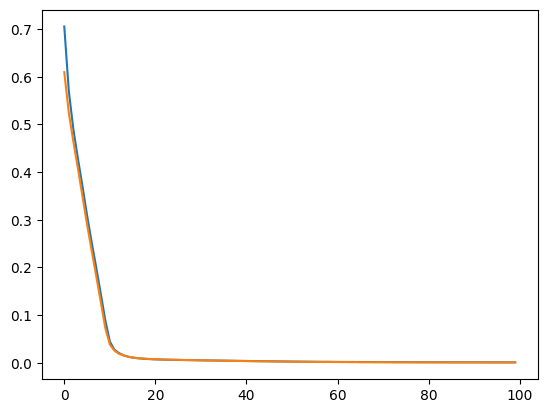

In [65]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
# plt.xlabel('epoch')
# plt.ylabel('loss')
# plt.legend(['train', 'validation'])

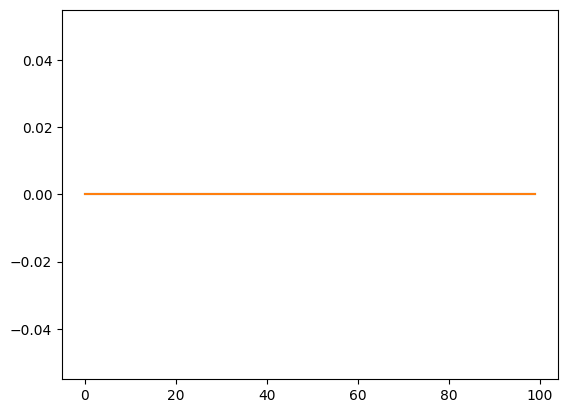

In [66]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])